# TimeMixer: Decomposable Multiscale Mixing for Time Series Forecasting

**Paper**: Shiyu Wang, Haixu Wu, Xiaoming Shi, Tengge Hu, Huakun Luo, Lintao Ma, James Y. Zhang, Jun Zhou. *TimeMixer: Decomposable Multiscale Mixing for Time Series Forecasting*. **ICLR 2024**. [arXiv:2405.14616](https://arxiv.org/abs/2405.14616)

**Official code**: [github.com/kwuking/TimeMixer](https://github.com/kwuking/TimeMixer) (`models/TimeMixer.py`, `layers/StandardNorm.py`, `layers/Autoformer_EncDec.py`, `layers/Embed.py`)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/manmeet3591/time_series/blob/main/timemixer_multiscale_mixing.ipynb)

**Key ideas**:
- **Multiscale views**: the input is average-pooled into $M+1$ scales ($96 \to 48 \to 24 \to 12$). Fine scales show detailed (seasonal) variation, coarse scales show macro (trend) variation.
- **Past-Decomposable-Mixing (PDM)**: each scale is decomposed into **season** and **trend** (moving average); seasons are mixed **bottom-up** (fine → coarse, since coarse seasonality is built from fine detail) and trends are mixed **top-down** (coarse → fine, since coarse trends are cleaner) with small MLPs along time.
- **Future-Multipredictor-Mixing (FMM)**: every scale gets its own linear predictor to the horizon; the $M+1$ forecasts are summed, ensembling complementary predictive skills.
- Fully MLP-based, channel-independent, with RevIN-style normalisation per scale.

This notebook re-implements TimeMixer from scratch in PyTorch, following the official code, and trains it with the official script `scripts/long_term_forecast/ETT_script/TimeMixer_ETTh1_unify.sh` (ETTh1, 96 → 96).

## Setup

Everything needed (PyTorch, NumPy, pandas, scikit-learn, matplotlib) is preinstalled on Colab, so there is no `%pip install` step.

In [1]:
import os, time, json, math, random
import numpy as np, pandas as pd, torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

SEED = 2024
def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
seed_everything()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| device:", device,
      "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "")

torch 2.12.1+cu130 | device: cuda | NVIDIA RTX PRO 6000 Blackwell Max-Q Workstation Edition


## Data: ETTh1 (standard benchmark split)

ETTh1 = hourly electricity-transformer data, 7 channels (`HUFL, HULL, MUFL, MULL, LUFL, LULL, OT`).
We use the standard Informer/Autoformer/TSLib borders: 12 months train, 4 months val, 4 months test, a
`StandardScaler` fitted on the train rows only, and metrics on the scaled data (what papers report).

The official code also feeds **calendar features** (`--embed timeF`, `--freq h`): hour-of-day, day-of-week,
day-of-month and day-of-year, each scaled to $[-0.5, 0.5]$. We compute them with the same borders and return
them from a small extension of the shared `WindowDataset` (the helper itself is unchanged).

In [2]:
URL = "https://raw.githubusercontent.com/zhouhaoyi/ETDataset/main/ETT-small/ETTh1.csv"

def load_etth1(lookback):
    df = pd.read_csv(URL)
    data = df.drop(columns=["date"]).values.astype(np.float32)
    n_tr, n_va, n_te = 12*30*24, 4*30*24, 4*30*24
    scaler = StandardScaler().fit(data[:n_tr])
    data = scaler.transform(data).astype(np.float32)
    train = data[:n_tr]
    val = data[n_tr - lookback: n_tr + n_va]
    test = data[n_tr + n_va - lookback: n_tr + n_va + n_te]
    return train, val, test, df.columns[1:].tolist()

class WindowDataset(torch.utils.data.Dataset):
    def __init__(self, arr, L, H, stride=1):
        self.arr, self.L, self.H = arr, L, H
        self.idx = np.arange(0, len(arr) - L - H + 1, stride)
    def __len__(self): return len(self.idx)
    def __getitem__(self, k):
        i = self.idx[k]
        return torch.from_numpy(self.arr[i:i+self.L]), torch.from_numpy(self.arr[i+self.L:i+self.L+self.H])

# --- extension: calendar features ("timeF", freq='h') with the same borders ---
def load_etth1_marks(lookback):
    d = pd.to_datetime(pd.read_csv(URL)["date"])
    marks = np.stack([d.dt.hour / 23.0 - 0.5,             # HourOfDay
                      d.dt.dayofweek / 6.0 - 0.5,         # DayOfWeek
                      (d.dt.day - 1) / 30.0 - 0.5,        # DayOfMonth
                      (d.dt.dayofyear - 1) / 365.0 - 0.5  # DayOfYear
                     ], 1).astype(np.float32)
    n_tr, n_va, n_te = 12*30*24, 4*30*24, 4*30*24
    return (marks[:n_tr], marks[n_tr - lookback: n_tr + n_va],
            marks[n_tr + n_va - lookback: n_tr + n_va + n_te])

class WindowDatasetMark(WindowDataset):
    """Same windows as WindowDataset, plus the calendar features of input and target steps."""
    def __init__(self, arr, marks, L, H, stride=1):
        super().__init__(arr, L, H, stride); self.marks = marks
    def __getitem__(self, k):
        x, y = super().__getitem__(k); i = self.idx[k]
        return (x, y, torch.from_numpy(self.marks[i:i+self.L]),
                torch.from_numpy(self.marks[i+self.L:i+self.L+self.H]))

L, H = 96, 96
train, val, test, cols = load_etth1(L)
m_train, m_val, m_test = load_etth1_marks(L)
train_ds = WindowDatasetMark(train, m_train, L, H)
val_ds   = WindowDatasetMark(val,   m_val,   L, H)
test_ds  = WindowDatasetMark(test,  m_test,  L, H)
print("channels:", cols)
print(f"windows  train={len(train_ds)}  val={len(val_ds)}  test={len(test_ds)}")

channels: ['HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT']
windows  train=8449  val=2785  test=2785


## Configuration (official `TimeMixer_ETTh1_unify.sh`, `ETTh1_96_96`)

| arg | value | arg | value |
|---|---|---|---|
| `seq_len` / `label_len` / `pred_len` | 96 / 0 / 96 | `e_layers` (PDM blocks) | 2 |
| `down_sampling_layers` | 3 | `down_sampling_window` | 2 |
| `down_sampling_method` | `avg` | `d_model` / `d_ff` | 16 / 32 |
| `channel_independence` | 1 (default) | `decomp_method` | `moving_avg`, kernel 25 (default) |
| `use_norm` | 1 (default) | `embed` | `timeF`, freq `h` |
| `dropout` | 0.1 (default) | `use_future_temporal_feature` | 0 (default) |
| `learning_rate` | 0.01 (Adam) | `lradj` | `TST` = OneCycleLR, `pct_start` 0.2 (default) |
| `batch_size` | 128 | `train_epochs` / `patience` | 10 / 10 |

In [3]:
class Config:
    seq_len, label_len, pred_len = L, 0, H
    enc_in = c_out = 7
    e_layers = 2
    d_model, d_ff = 16, 32
    down_sampling_layers, down_sampling_window, down_sampling_method = 3, 2, "avg"
    channel_independence = 1
    decomp_method, moving_avg, top_k = "moving_avg", 25, 5
    use_norm = 1
    dropout = 0.1
    learning_rate, pct_start = 0.01, 0.2
    batch_size = 128
    train_epochs, patience = 10, 10
cfg = Config()
print("scales:", [cfg.seq_len // cfg.down_sampling_window ** i for i in range(cfg.down_sampling_layers + 1)])

scales: [96, 48, 24, 12]


## Component 1: Building blocks: normalisation, embedding, series decomposition

- **`Normalize`** (RevIN): per window and channel, $\tilde x = \gamma \frac{x-\mu}{\sigma} + \beta$ with learnable $\gamma,\beta$ per channel. One instance per scale; the forecast is de-normalised with the finest scale's statistics.
- **Embedding** (`DataEmbedding_wo_pos`): with channel independence every channel is a separate univariate series, so the value embedding is a `Conv1d(1 → d_model, k=3, circular)`, plus a linear projection of the 4 calendar features. No positional embedding.
- **`series_decomp`**: trend $= \mathrm{AvgPool}_{25}(\mathrm{Padding}(x))$ (edge-replicate padding keeps the length), season $= x - $ trend. (The alternative `DFT_series_decomp` keeps the top-$k$ Fourier modes as season; not used for ETTh1.)

In [4]:
class Normalize(nn.Module):
    def __init__(self, num_features, eps=1e-5, affine=False, subtract_last=False, non_norm=False):
        super().__init__()
        self.num_features, self.eps, self.affine = num_features, eps, affine
        self.subtract_last, self.non_norm = subtract_last, non_norm
        if affine:
            self.affine_weight = nn.Parameter(torch.ones(num_features))
            self.affine_bias = nn.Parameter(torch.zeros(num_features))
    def forward(self, x, mode):
        if mode == "norm":
            dims = tuple(range(1, x.ndim - 1))
            if self.subtract_last: self.last = x[:, -1, :].unsqueeze(1)
            else: self.mean = torch.mean(x, dim=dims, keepdim=True).detach()
            self.stdev = torch.sqrt(torch.var(x, dim=dims, keepdim=True, unbiased=False) + self.eps).detach()
            if self.non_norm: return x
            x = (x - (self.last if self.subtract_last else self.mean)) / self.stdev
            if self.affine: x = x * self.affine_weight + self.affine_bias
            return x
        elif mode == "denorm":
            if self.non_norm: return x
            if self.affine: x = (x - self.affine_bias) / (self.affine_weight + self.eps * self.eps)
            x = x * self.stdev
            return x + (self.last if self.subtract_last else self.mean)
        raise NotImplementedError

class TokenEmbedding(nn.Module):
    def __init__(self, c_in, d_model):
        super().__init__()
        self.tokenConv = nn.Conv1d(c_in, d_model, kernel_size=3, padding=1, padding_mode="circular", bias=False)
        nn.init.kaiming_normal_(self.tokenConv.weight, mode="fan_in", nonlinearity="leaky_relu")
    def forward(self, x):
        return self.tokenConv(x.permute(0, 2, 1)).transpose(1, 2)

class DataEmbedding_wo_pos(nn.Module):
    def __init__(self, c_in, d_model, dropout=0.1, d_mark=4):
        super().__init__()
        self.value_embedding = TokenEmbedding(c_in, d_model)
        self.temporal_embedding = nn.Linear(d_mark, d_model, bias=False)   # TimeFeatureEmbedding (timeF)
        self.dropout = nn.Dropout(dropout)
    def forward(self, x, x_mark):
        if x is None and x_mark is not None:
            return self.temporal_embedding(x_mark)
        x = self.value_embedding(x) if x_mark is None else self.value_embedding(x) + self.temporal_embedding(x_mark)
        return self.dropout(x)

class moving_avg(nn.Module):
    def __init__(self, kernel_size, stride=1):
        super().__init__()
        self.kernel_size = kernel_size
        self.avg = nn.AvgPool1d(kernel_size=kernel_size, stride=stride, padding=0)
    def forward(self, x):                              # [B, T, C]
        front = x[:, 0:1, :].repeat(1, (self.kernel_size - 1) // 2, 1)
        end = x[:, -1:, :].repeat(1, (self.kernel_size - 1) // 2, 1)
        x = torch.cat([front, x, end], dim=1)
        return self.avg(x.permute(0, 2, 1)).permute(0, 2, 1)

class series_decomp(nn.Module):
    def __init__(self, kernel_size):
        super().__init__()
        self.moving_avg = moving_avg(kernel_size, stride=1)
    def forward(self, x):
        trend = self.moving_avg(x)
        return x - trend, trend                        # (season, trend)

class DFT_series_decomp(nn.Module):
    def __init__(self, top_k=5):
        super().__init__(); self.top_k = top_k
    def forward(self, x):
        xf = torch.fft.rfft(x); freq = abs(xf); freq[0] = 0
        top_k_freq, _ = torch.topk(freq, self.top_k)
        xf[freq <= top_k_freq.min()] = 0
        x_season = torch.fft.irfft(xf)
        return x_season, x - x_season

## Component 2: Multiscale season mixing (bottom-up) and trend mixing (top-down)

With seasonal parts $\{s_0, \dots, s_M\}$ and trend parts $\{t_0, \dots, t_M\}$ at lengths $\lfloor L/2^m \rfloor$ (each an MLP over the **time** axis, applied per embedding dimension):

$$\text{for } m = 1 \dots M:\quad s_m \leftarrow s_m + \mathrm{BottomUpMixing}(s_{m-1}) \qquad (\text{Linear}_{L/2^{m-1}\to L/2^m} \to \text{GELU} \to \text{Linear})$$

$$\text{for } m = M-1 \dots 0:\quad t_m \leftarrow t_m + \mathrm{TopDownMixing}(t_{m+1}) \qquad (\text{Linear}_{L/2^{m+1}\to L/2^m} \to \text{GELU} \to \text{Linear})$$

Note the recursion uses the already-mixed coarser/finer term, so information flows across all scales.

In [5]:
class MultiScaleSeasonMixing(nn.Module):
    """Bottom-up: fine (high-resolution) -> coarse."""
    def __init__(self, configs):
        super().__init__()
        w = configs.down_sampling_window
        self.down_sampling_layers = nn.ModuleList([
            nn.Sequential(nn.Linear(configs.seq_len // w ** i, configs.seq_len // w ** (i + 1)), nn.GELU(),
                          nn.Linear(configs.seq_len // w ** (i + 1), configs.seq_len // w ** (i + 1)))
            for i in range(configs.down_sampling_layers)])
    def forward(self, season_list):                    # each [B, d_model, T_m]
        out_high, out_low = season_list[0], season_list[1]
        out_season_list = [out_high.permute(0, 2, 1)]
        for i in range(len(season_list) - 1):
            out_low = out_low + self.down_sampling_layers[i](out_high)
            out_high = out_low
            if i + 2 <= len(season_list) - 1:
                out_low = season_list[i + 2]
            out_season_list.append(out_high.permute(0, 2, 1))
        return out_season_list

class MultiScaleTrendMixing(nn.Module):
    """Top-down: coarse (low-resolution) -> fine."""
    def __init__(self, configs):
        super().__init__()
        w = configs.down_sampling_window
        self.up_sampling_layers = nn.ModuleList([
            nn.Sequential(nn.Linear(configs.seq_len // w ** (i + 1), configs.seq_len // w ** i), nn.GELU(),
                          nn.Linear(configs.seq_len // w ** i, configs.seq_len // w ** i))
            for i in reversed(range(configs.down_sampling_layers))])
    def forward(self, trend_list):
        rev = trend_list.copy(); rev.reverse()
        out_low, out_high = rev[0], rev[1]
        out_trend_list = [out_low.permute(0, 2, 1)]
        for i in range(len(rev) - 1):
            out_high = out_high + self.up_sampling_layers[i](out_low)
            out_low = out_high
            if i + 2 <= len(rev) - 1:
                out_high = rev[i + 2]
            out_trend_list.append(out_low.permute(0, 2, 1))
        out_trend_list.reverse()
        return out_trend_list

## Component 3: Past-Decomposable-Mixing (PDM) block

$$s^l_m, t^l_m = \mathrm{SeriesDecomp}(x^{l-1}_m),\qquad
x^l_m = x^{l-1}_m + \mathrm{FeedForward}\big(\mathrm{S\text{-}Mix}(\{s^l_m\})_m + \mathrm{T\text{-}Mix}(\{t^l_m\})_m\big)$$

`FeedForward` = `Linear(d_model→d_ff) → GELU → Linear(d_ff→d_model)` over the hidden dimension (`out_cross_layer`). With `channel_independence=0` an extra channel-mixing MLP would be applied to season and trend before mixing; here it is unused. (The `layer_norm` / `dropout` members of the official block are defined but never called; they are kept so the parameter count matches.)

In [6]:
class PastDecomposableMixing(nn.Module):
    def __init__(self, configs):
        super().__init__()
        self.layer_norm = nn.LayerNorm(configs.d_model)      # defined but unused in the official forward
        self.dropout = nn.Dropout(configs.dropout)           # idem
        self.channel_independence = configs.channel_independence
        if configs.decomp_method == "moving_avg":
            self.decompsition = series_decomp(configs.moving_avg)
        elif configs.decomp_method == "dft_decomp":
            self.decompsition = DFT_series_decomp(configs.top_k)
        else:
            raise ValueError("decomposition error")
        if configs.channel_independence == 0:
            self.cross_layer = nn.Sequential(nn.Linear(configs.d_model, configs.d_ff), nn.GELU(),
                                             nn.Linear(configs.d_ff, configs.d_model))
        self.mixing_multi_scale_season = MultiScaleSeasonMixing(configs)
        self.mixing_multi_scale_trend = MultiScaleTrendMixing(configs)
        self.out_cross_layer = nn.Sequential(nn.Linear(configs.d_model, configs.d_ff), nn.GELU(),
                                             nn.Linear(configs.d_ff, configs.d_model))

    def forward(self, x_list):                          # list of [B*N, T_m, d_model]
        length_list = [x.size(1) for x in x_list]
        season_list, trend_list = [], []
        for x in x_list:
            season, trend = self.decompsition(x)
            if self.channel_independence == 0:
                season, trend = self.cross_layer(season), self.cross_layer(trend)
            season_list.append(season.permute(0, 2, 1))  # mix along time
            trend_list.append(trend.permute(0, 2, 1))
        out_season_list = self.mixing_multi_scale_season(season_list)
        out_trend_list = self.mixing_multi_scale_trend(trend_list)
        out_list = []
        for ori, out_season, out_trend, length in zip(x_list, out_season_list, out_trend_list, length_list):
            out = out_season + out_trend
            if self.channel_independence:
                out = ori + self.out_cross_layer(out)
            out_list.append(out[:, :length, :])
        return out_list

## Component 4: Full model: multiscale inputs → PDM encoder → Future-Multipredictor-Mixing

1. **Multiscale inputs**: `AvgPool1d(2)` applied 3 times: $x_0 \in \mathbb{R}^{96}$, $x_1 \in \mathbb{R}^{48}$, $x_2 \in \mathbb{R}^{24}$, $x_3 \in \mathbb{R}^{12}$; calendar features are subsampled with `[:, ::2]`.
2. Per-scale RevIN normalisation, channel-independent reshape $[B, T_m, N] \to [B\cdot N, T_m, 1]$, embedding.
3. `e_layers` PDM blocks.
4. **FMM**: $\hat x_m = \mathrm{Proj}\big(\mathrm{Predictor}_m(x^{L}_m)\big)$ with $\mathrm{Predictor}_m: \mathbb{R}^{L/2^m} \to \mathbb{R}^{H}$ along time and $\mathrm{Proj}: d_{\text{model}} \to 1$; then $\hat x = \sum_m \hat x_m$, and de-normalise.

> **Note (faithful to the official code):** in the channel-independent path the official code reshapes values to
> $[B\cdot N, \dots]$ with index $b\cdot N + n$, but repeats the calendar features with `x_mark.repeat(N, 1, 1)`, which
> orders them as $n\cdot B + b$. So, inside a batch, most series receive the calendar features of a *different*
> sample. We keep this behaviour (flag `OFFICIAL_MARK_REPEAT = True`) to reproduce the reported numbers; setting it
> to `False` uses the aligned `repeat_interleave`.

In [7]:
OFFICIAL_MARK_REPEAT = True

class TimeMixer(nn.Module):
    def __init__(self, configs):
        super().__init__()
        self.configs = configs
        self.seq_len, self.pred_len = configs.seq_len, configs.pred_len
        self.channel_independence = configs.channel_independence
        self.pdm_blocks = nn.ModuleList([PastDecomposableMixing(configs) for _ in range(configs.e_layers)])
        self.preprocess = series_decomp(configs.moving_avg)
        c_in = 1 if configs.channel_independence == 1 else configs.enc_in
        self.enc_embedding = DataEmbedding_wo_pos(c_in, configs.d_model, configs.dropout)
        self.layer = configs.e_layers
        self.normalize_layers = nn.ModuleList([
            Normalize(configs.enc_in, affine=True, non_norm=configs.use_norm == 0)
            for _ in range(configs.down_sampling_layers + 1)])
        w = configs.down_sampling_window
        self.predict_layers = nn.ModuleList([nn.Linear(configs.seq_len // w ** i, configs.pred_len)
                                             for i in range(configs.down_sampling_layers + 1)])
        if configs.channel_independence == 1:
            self.projection_layer = nn.Linear(configs.d_model, 1, bias=True)
        else:
            self.projection_layer = nn.Linear(configs.d_model, configs.c_out, bias=True)
            self.out_res_layers = nn.ModuleList([nn.Linear(configs.seq_len // w ** i, configs.seq_len // w ** i)
                                                 for i in range(configs.down_sampling_layers + 1)])
            self.regression_layers = nn.ModuleList([nn.Linear(configs.seq_len // w ** i, configs.pred_len)
                                                    for i in range(configs.down_sampling_layers + 1)])

    def multi_scale_process_inputs(self, x_enc, x_mark_enc):
        c = self.configs
        if c.down_sampling_method == "max":
            down_pool = nn.MaxPool1d(c.down_sampling_window, return_indices=False)
        elif c.down_sampling_method == "avg":
            down_pool = nn.AvgPool1d(c.down_sampling_window)
        else:
            return [x_enc], [x_mark_enc]
        x_ori = x_enc.permute(0, 2, 1)                  # B,T,C -> B,C,T
        x_list, mark_list = [x_enc], [x_mark_enc]
        for _ in range(c.down_sampling_layers):
            x_ori = down_pool(x_ori)
            x_list.append(x_ori.permute(0, 2, 1))
            if x_mark_enc is not None:
                x_mark_enc = x_mark_enc[:, ::c.down_sampling_window, :]
                mark_list.append(x_mark_enc)
        return x_list, (mark_list if mark_list[0] is not None else None)

    def forecast(self, x_enc, x_mark_enc):
        x_enc, x_mark_enc = self.multi_scale_process_inputs(x_enc, x_mark_enc)
        x_list, x_mark_list = [], []
        for i, x in enumerate(x_enc):
            B, T, N = x.size()
            x = self.normalize_layers[i](x, "norm")
            if self.channel_independence == 1:
                x = x.permute(0, 2, 1).contiguous().reshape(B * N, T, 1)
            x_list.append(x)
            if x_mark_enc is not None:
                xm = x_mark_enc[i]
                if self.channel_independence == 1:
                    xm = xm.repeat(N, 1, 1) if OFFICIAL_MARK_REPEAT else xm.repeat_interleave(N, 0)
                x_mark_list.append(xm)
        # pre_enc: identity when channel-independent, else (season, trend) of each scale
        if self.channel_independence == 1:
            x_list = (x_list, None)
        else:
            x_list = tuple(map(list, zip(*[self.preprocess(x) for x in x_list])))
        enc_out_list = [self.enc_embedding(x, x_mark_list[i] if x_mark_enc is not None else None)
                        for i, x in enumerate(x_list[0])]
        for i in range(self.layer):                     # Past-Decomposable-Mixing
            enc_out_list = self.pdm_blocks[i](enc_out_list)
        dec_out_list = self.future_multi_mixing(B, enc_out_list, x_list)
        dec_out = torch.stack(dec_out_list, dim=-1).sum(-1)
        return self.normalize_layers[0](dec_out, "denorm")

    def future_multi_mixing(self, B, enc_out_list, x_list):
        dec_out_list = []
        if self.channel_independence == 1:
            for i, enc_out in enumerate(enc_out_list):
                dec_out = self.predict_layers[i](enc_out.permute(0, 2, 1)).permute(0, 2, 1)   # [B*N, H, d]
                dec_out = self.projection_layer(dec_out)                                      # [B*N, H, 1]
                dec_out = dec_out.reshape(B, self.configs.c_out, self.pred_len).permute(0, 2, 1).contiguous()
                dec_out_list.append(dec_out)
        else:
            for i, (enc_out, out_res) in enumerate(zip(enc_out_list, x_list[1])):
                dec_out = self.predict_layers[i](enc_out.permute(0, 2, 1)).permute(0, 2, 1)
                dec_out = self.projection_layer(dec_out)
                out_res = self.regression_layers[i](self.out_res_layers[i](out_res.permute(0, 2, 1))).permute(0, 2, 1)
                dec_out_list.append(dec_out + out_res)
        return dec_out_list

    def forward(self, x_enc, x_mark_enc=None):
        return self.forecast(x_enc, x_mark_enc)

seed_everything()
model = TimeMixer(cfg).to(device)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"TimeMixer parameters: {n_params:,}")
with torch.no_grad():
    x, y, xm, ym = next(iter(torch.utils.data.DataLoader(train_ds, batch_size=4)))
    print("forward:", tuple(x.shape), "->", tuple(model(x.to(device), xm.to(device)).shape))

TimeMixer parameters: 75,497


forward: (4, 96, 7) -> (4, 96, 7)


## Training (official `exp_long_term_forecasting.py` recipe)

Adam with **OneCycleLR** (`lradj=TST`: max lr 0.01, `pct_start=0.2`, stepped every batch over 10 epochs), MSE loss,
batch 128 with `drop_last=True` for the shuffled training loader (the official default), early stopping on validation MSE
with patience 10 (so all 10 epochs run), and the best-validation checkpoint is restored for testing.

In [8]:
@torch.no_grad()
def evaluate(model, ds, batch_size):
    """Exact MSE/MAE over all windows, horizon steps and channels (no dropped batches)."""
    model.eval()
    se = ae = n = 0.0
    preds = []
    for x, y, xm, ym in torch.utils.data.DataLoader(ds, batch_size=batch_size, shuffle=False):
        x, y, xm = x.to(device), y.to(device), xm.to(device)
        p = model(x, xm)
        se += ((p - y) ** 2).sum().item(); ae += (p - y).abs().sum().item(); n += y.numel()
        preds.append(p.cpu())
    return se / n, ae / n, torch.cat(preds).numpy()

In [9]:
seed_everything()
train_loader = torch.utils.data.DataLoader(train_ds, batch_size=cfg.batch_size, shuffle=True, drop_last=True)
optim = torch.optim.Adam(model.parameters(), lr=cfg.learning_rate)
sched = torch.optim.lr_scheduler.OneCycleLR(optim, max_lr=cfg.learning_rate, steps_per_epoch=len(train_loader),
                                            epochs=cfg.train_epochs, pct_start=cfg.pct_start)
criterion = nn.MSELoss()

best_val, best_state, bad = float("inf"), None, 0
t0 = time.time()
for epoch in range(cfg.train_epochs):
    model.train(); losses = []; te = time.time()
    for x, y, xm, ym in train_loader:
        x, y, xm = x.to(device), y.to(device), xm.to(device)
        optim.zero_grad()
        loss = criterion(model(x, xm), y)
        loss.backward(); optim.step(); sched.step()
        losses.append(loss.item())
    val_mse, _, _ = evaluate(model, val_ds, cfg.batch_size)
    print(f"epoch {epoch+1:2d} | train {np.mean(losses):.4f} | val {val_mse:.4f} "
          f"| lr {sched.get_last_lr()[0]:.2e} | {time.time()-te:.1f}s")
    if val_mse < best_val:
        best_val, bad = val_mse, 0
        best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
    else:
        bad += 1
        if bad >= cfg.patience:
            print("early stopping"); break
train_seconds = time.time() - t0
model.load_state_dict(best_state)
print(f"training time: {train_seconds:.1f}s | best val MSE {best_val:.4f}")

epoch  1 | train 0.6327 | val 0.7305 | lr 5.26e-03 | 1.0s


epoch  2 | train 0.3699 | val 0.6946 | lr 1.00e-02 | 0.9s


epoch  3 | train 0.3518 | val 0.6888 | lr 9.61e-03 | 0.9s


epoch  4 | train 0.3422 | val 0.7043 | lr 8.51e-03 | 0.9s


epoch  5 | train 0.3351 | val 0.7099 | lr 6.89e-03 | 0.9s


epoch  6 | train 0.3265 | val 0.7120 | lr 4.97e-03 | 0.9s


epoch  7 | train 0.3172 | val 0.7244 | lr 3.06e-03 | 0.9s


epoch  8 | train 0.3095 | val 0.7339 | lr 1.44e-03 | 1.0s


epoch  9 | train 0.3029 | val 0.7414 | lr 3.69e-04 | 0.9s


epoch 10 | train 0.2992 | val 0.7442 | lr 1.29e-07 | 0.9s
training time: 9.2s | best val MSE 0.6888


## Test evaluation (all 2785 stride-1 test windows)

In [10]:
test_mse, test_mae, test_pred = evaluate(model, test_ds, cfg.batch_size)
PAPER_MSE, PAPER_MAE = 0.375, 0.400   # TimeMixer paper, Table 13 (ETTh1, 96->96, unified L=96)
print(f"{'':18s}{'MSE':>8s}{'MAE':>8s}")
print(f"{'TimeMixer (ours)':18s}{test_mse:8.3f}{test_mae:8.3f}")
print(f"{'TimeMixer (paper)':18s}{PAPER_MSE:8.3f}{PAPER_MAE:8.3f}")
print(f"{'TimesNet (TSLib)':18s}{0.384:8.3f}{0.402:8.3f}")

                       MSE     MAE
TimeMixer (ours)     0.384   0.399
TimeMixer (paper)    0.375   0.400
TimesNet (TSLib)     0.384   0.402


## What do the scales contribute? (Future-Multipredictor-Mixing)

FMM sums one forecast per scale. Below we split the (normalised-space) forecast of one test window into its four per-scale predictors (right), next to the avg-pooled inputs at each scale (left).

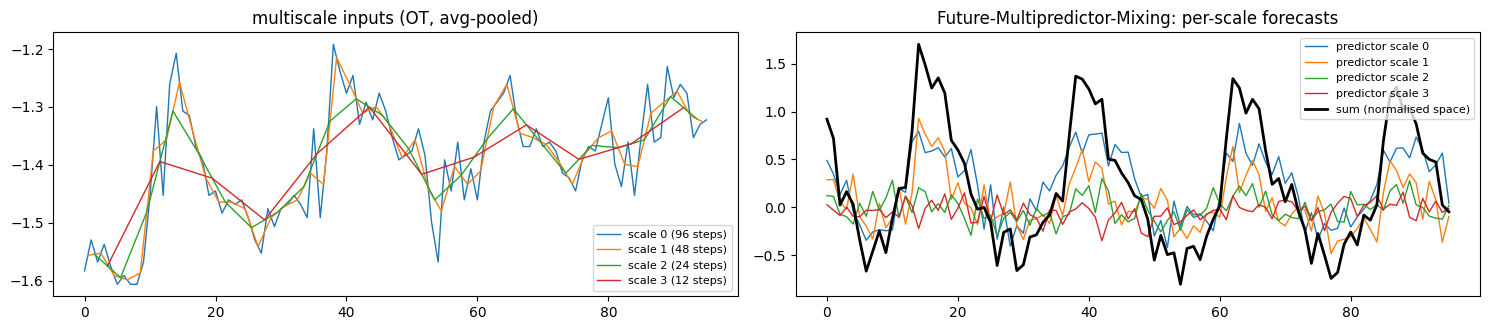

In [11]:
model.eval()
k = len(test_ds) // 2
x, y, xm, ym = [t.unsqueeze(0).to(device) for t in test_ds[k]]
ot = cols.index("OT")
with torch.no_grad():
    xs, ms = model.multi_scale_process_inputs(x, xm)
    xl, ml = [], []
    for i, xi in enumerate(xs):
        B, T, N = xi.shape
        xl.append(model.normalize_layers[i](xi, "norm").permute(0, 2, 1).reshape(B * N, T, 1))
        ml.append(ms[i].repeat(N, 1, 1))
    enc = [model.enc_embedding(a, b) for a, b in zip(xl, ml)]
    for blk in model.pdm_blocks: enc = blk(enc)
    parts = model.future_multi_mixing(1, enc, (xl, None))
fig, ax = plt.subplots(1, 2, figsize=(15, 3.4))
for i, xi in enumerate(xs):
    T = xi.shape[1]
    tt = np.arange(T) * 2 ** i + (2 ** i - 1) / 2
    ax[0].plot(tt, xi[0, :, ot].cpu(), lw=1, label=f"scale {i} ({T} steps)")
ax[0].set_title("multiscale inputs (OT, avg-pooled)"); ax[0].legend(fontsize=8)
for i, p in enumerate(parts):
    ax[1].plot(p[0, :, ot].cpu(), lw=1, label=f"predictor scale {i}")
ax[1].plot(torch.stack(parts, -1).sum(-1)[0, :, ot].cpu(), "k", lw=2, label="sum (normalised space)")
ax[1].set_title("Future-Multipredictor-Mixing: per-scale forecasts"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## Forecast plot (OT channel)

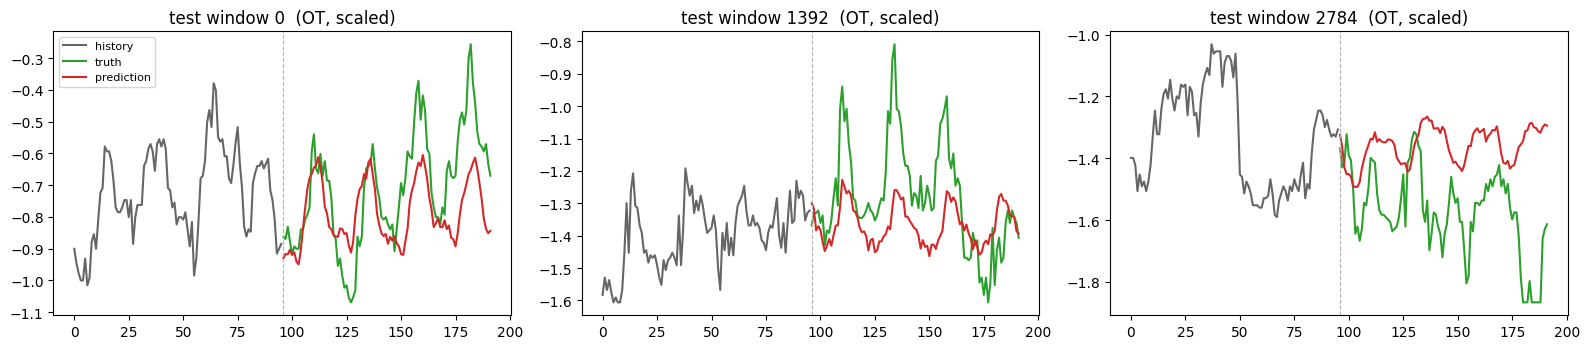

In [12]:
# Forecast plot for the OT channel (oil temperature) on a few test windows
ot = cols.index("OT")
fig, axes = plt.subplots(1, 3, figsize=(16, 3.6), sharey=False)
for ax, k in zip(axes, [0, len(test_ds) // 2, len(test_ds) - 1]):
    x, y, _, _ = test_ds[k]
    ax.plot(np.arange(L), x[:, ot], color="0.4", label="history")
    ax.plot(np.arange(L, L + H), y[:, ot], color="tab:green", label="truth")
    ax.plot(np.arange(L, L + H), test_pred[k, :, ot], color="tab:red", label="prediction")
    ax.axvline(L, color="0.7", ls="--", lw=0.8)
    ax.set_title(f"test window {k}  (OT, scaled)")
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

## Results

In [13]:
results = {
    "model": "TimeMixer", "paper": "TimeMixer: Decomposable Multiscale Mixing for Time Series Forecasting (arXiv:2405.14616)",
    "venue": "ICLR 2024", "type": "supervised", "lookback": L, "horizon": H,
    "mse": round(float(test_mse), 4), "mae": round(float(test_mae), 4),
    "paper_mse": PAPER_MSE, "paper_mae": PAPER_MAE,
    "params": int(n_params), "train_or_infer_seconds": round(float(train_seconds), 1),
    "notes": ("From-scratch PyTorch re-implementation of kwuking/TimeMixer models/TimeMixer.py; hyperparameters from "
              "TimeMixer_ETTh1_unify.sh (e_layers=2, d_model=16, d_ff=32, 3 avg down-sampling layers x2, "
              "channel independence, moving_avg 25, lr=0.01 OneCycleLR pct_start 0.2, batch 128, 10 epochs, "
              "patience 10, timeF calendar features incl. the official x_mark.repeat ordering). Seed 2024, single run. "
              "Test on all 2785 stride-1 windows (official loader drops the last incomplete test batch)."),
}
print(json.dumps(results, indent=2))
try:
    with open("results_timemixer_multiscale_mixing.json", "w") as f:
        json.dump(results, f, indent=2)
except Exception as ex:
    print("could not write results file:", ex)

{
  "model": "TimeMixer",
  "paper": "TimeMixer: Decomposable Multiscale Mixing for Time Series Forecasting (arXiv:2405.14616)",
  "venue": "ICLR 2024",
  "type": "supervised",
  "lookback": 96,
  "horizon": 96,
  "mse": 0.3838,
  "mae": 0.3994,
  "paper_mse": 0.375,
  "paper_mae": 0.4,
  "params": 75497,
  "train_or_infer_seconds": 9.2,
  "notes": "From-scratch PyTorch re-implementation of kwuking/TimeMixer models/TimeMixer.py; hyperparameters from TimeMixer_ETTh1_unify.sh (e_layers=2, d_model=16, d_ff=32, 3 avg down-sampling layers x2, channel independence, moving_avg 25, lr=0.01 OneCycleLR pct_start 0.2, batch 128, 10 epochs, patience 10, timeF calendar features incl. the official x_mark.repeat ordering). Seed 2024, single run. Test on all 2785 stride-1 windows (official loader drops the last incomplete test batch)."
}


## Using your own data

1. Replace `load_etth1` / `load_etth1_marks` with your own loader returning `train / val / test` arrays of shape `[time, channels]` (scaled with training statistics) and matching calendar features (or pass `x_mark=None`: the embedding then uses the value term only).
2. Set `Config.enc_in = c_out = <number of channels>` and `seq_len` / `pred_len`. Keep `seq_len` divisible by `down_sampling_window ** down_sampling_layers` (here 8) so every scale has an integer length.
3. For many correlated channels (Electricity, Traffic) the official scripts keep `channel_independence=1` but use larger `d_model`/`d_ff`; with `channel_independence=0` the model adds channel-mixing MLPs and a residual regression path (already implemented above).

```python
cfg.enc_in = cfg.c_out = my_train.shape[1]
cfg.seq_len, cfg.pred_len = 192, 24
model = TimeMixer(cfg).to(device)
```